# 01 – Exploratory Data Analysis

**Project:** Predicting Agricultural Drought Risk (Group 16)

This notebook explores the weekly drought dataset built by `src/data.py`: how the drought classes are distributed, how drought varies over time, space and season, how persistent drought is from week to week, and which weather and soil variables relate to it. The findings motivate the modelling choices (class imbalance handling, persistence baseline, rolling-window features).

**How to run:** from the project root, start Jupyter (`py -m jupyter notebook`) and run all cells. Every figure is saved to `reports/figures/` with the file name shown under it, so the report figures can be recreated by re-running this notebook.

In [15]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import CLASS_NAMES, FIGURES_DIR, RAW_DIR, SEED, WEATHER_COLS
from src.data import build_weekly_dataset, load_soil
from src.features import add_features

# ---- Settings -------------------------------------------------------------
DATA_DIR = RAW_DIR      # use ROOT / "data" / "sample" for a quick test run
MAX_COUNTIES = 300      # None = all 3,108 counties (slow, needs lots of RAM)
# ---------------------------------------------------------------------------

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SPLIT_COLORS = {"train": "#4C72B0", "validation": "#DD8452", "test": "#55A868"}


def save(fig, name):
    """Save a figure to reports/figures/ so the report can reuse it."""
    path = FIGURES_DIR / f"eda_{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved {path.relative_to(ROOT)}")

## 1. Load the weekly data

The raw files contain one row per county and day. `build_weekly_dataset` groups the days into USDM weeks (each week ends on the day the drought map is valid) and caches the result in `data/processed/`, so only the first run is slow.

In [16]:
weekly = build_weekly_dataset(DATA_DIR, max_counties=MAX_COUNTIES, seed=SEED)
soil = load_soil(DATA_DIR)
weekly["drought_class"] = weekly["score"].round().clip(0, 5).astype(int)

print(f"Weekly rows: {len(weekly):,}")
print(f"Counties:    {weekly['fips'].nunique():,}")
weekly.head()

Loading cached weekly data from C:\Users\louis_f9bsay\drought-prediction\data\processed\weekly_raw_300c_seed42.pkl
Weekly rows: 327,704
Counties:    299


,fips,date,PRECTOT,PS,QV2M,T2M,T2MDEW,T2MWET,T2M_MAX,T2M_MIN,...,WS10M_MAX,WS10M_MIN,WS10M_RANGE,WS50M,WS50M_MAX,WS50M_MIN,WS50M_RANGE,score,split,drought_class
0,1043,2000-01-04,24.650000,99.075001,8.875000,13.640000,11.367500,11.370000,21.48,0.40,...,7.01,2.365000,2.807500,6.800000,11.85,5.150000,3.257500,2.0334,train,2
1,1043,2000-01-11,31.740000,99.421428,4.914286,7.077143,2.198571,2.242857,15.86,-4.01,...,5.30,1.330000,2.264286,4.627143,10.30,2.250000,4.905714,2.0000,train,2
2,1043,2000-01-18,9.230000,100.032859,5.694286,7.660000,4.297143,4.332857,18.98,-3.82,...,5.05,1.935714,1.890000,5.398571,8.02,3.645714,3.531429,2.0000,train,2
3,1043,2000-01-25,23.960001,99.022859,3.191429,0.514286,-3.361429,-3.275714,10.25,-7.31,...,5.79,1.678571,2.591429,5.157143,9.56,3.148571,3.758571,2.0000,train,2
4,1043,2000-02-01,18.160002,99.800001,2.838571,-1.161429,-4.290000,-4.214286,8.00,-7.17,...,4.43,1.225714,2.445714,4.495714,7.18,2.300000,3.807143,2.0000,train,2


In [17]:
split_summary = (
    weekly.groupby("split", sort=False)
    .agg(rows=("fips", "size"), counties=("fips", "nunique"),
         first_week=("date", "min"), last_week=("date", "max"),
         mean_score=("score", "mean"))
)
split_summary

,rows,counties,first_week,last_week,mean_score
split,,,,,
train,265213,299,2000-01-04,2016-12-27,0.814064
validation,31096,299,2017-01-03,2018-12-25,0.570210
test,31395,299,2019-01-01,2020-12-29,0.439630


## 2. Data quality

Check for missing values and implausible ranges before modelling.

In [18]:
missing = weekly.isna().sum()
print("Missing values per column (weekly data):")
print(missing[missing > 0] if missing.any() else "None")
print(f"\nSoil table: {soil.shape[0]:,} counties x {soil.shape[1]} columns, "
      f"{soil.isna().sum().sum()} missing values")

weekly[WEATHER_COLS + ["score"]].describe().T.round(2)

Missing values per column (weekly data):
None

Soil table: 3,109 counties x 32 columns, 0 missing values


,count,mean,std,min,25%,50%,75%,max
PRECTOT,327704.0,18.37,20.94,0.00,3.38,11.81,26.17,688.71
PS,327704.0,96.23,6.14,68.79,95.66,98.14,99.70,103.01
QV2M,327704.0,7.69,4.39,0.35,3.94,6.80,10.99,20.35
T2M,327704.0,12.30,10.68,-27.47,4.09,13.23,21.32,37.28
T2MDEW,327704.0,6.58,9.68,-28.98,-0.97,6.98,14.76,25.48
T2MWET,327704.0,6.62,9.61,-27.77,-0.92,6.97,14.75,25.48
T2M_MAX,327704.0,22.61,10.39,-19.41,15.91,24.43,30.56,47.88
T2M_MIN,327704.0,3.05,11.18,-45.21,-4.76,3.00,12.04,28.30
T2M_RANGE,327704.0,11.27,2.89,1.26,9.37,11.29,13.18,22.81
TS,327704.0,12.36,10.93,-28.58,3.95,13.28,21.52,39.35


## 3. Target: distribution of drought classes

The USDM score runs from 0 (no drought) to 5 (D4, exceptional drought). Rounded, it gives six classes.

Saved reports\figures\eda_class_distribution.png


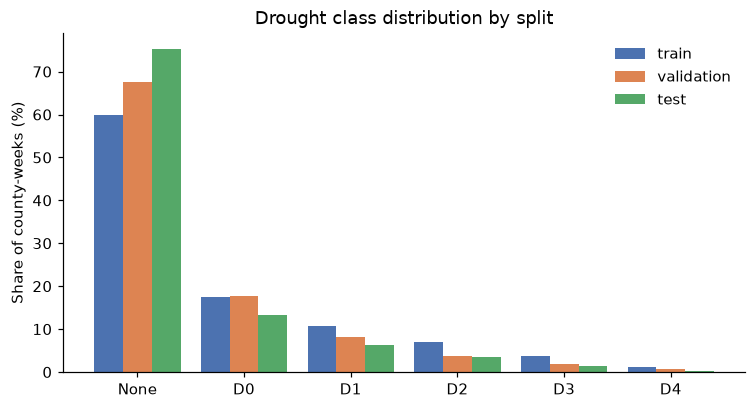

,None,D0,D1,D2,D3,D4
split,,,,,,
train,59.8,17.5,10.7,7.0,3.8,1.3
validation,67.7,17.8,8.2,3.7,1.9,0.8
test,75.2,13.2,6.4,3.5,1.3,0.3


In [19]:
class_share = (
    weekly.groupby("split", sort=False)["drought_class"]
    .value_counts(normalize=True)
    .unstack(fill_value=0)
    .reindex(columns=range(6), fill_value=0)
    * 100
)
class_share.columns = CLASS_NAMES

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(CLASS_NAMES))
width = 0.27
for i, split in enumerate(class_share.index):
    ax.bar(x + (i - 1) * width, class_share.loc[split], width,
           label=split, color=SPLIT_COLORS[split])
ax.set_xticks(x, CLASS_NAMES)
ax.set_ylabel("Share of county-weeks (%)")
ax.set_title("Drought class distribution by split")
ax.legend(frameon=False)
save(fig, "class_distribution")
plt.show()

class_share.round(1)

**What to look for:** most county-weeks have no drought, while D3–D4 are rare. Accuracy alone would therefore be misleading (always predicting "None" already scores high), which is why the models are compared on **macro F1** and use class weights. The class mix also differs between splits, because drought years are unevenly spread over time.

## 4. Drought over time

Share of counties in drought (D1 or worse) each week, with the three splits shaded.

Saved reports\figures\eda_drought_over_time.png


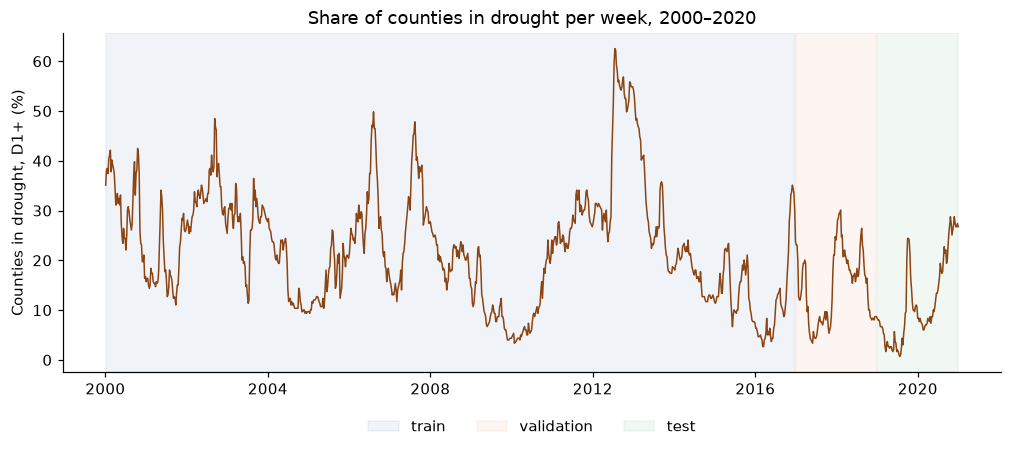

Years with the highest average share of counties in drought:
date
2012    42.6 %
2002    33.2 %
2000    31.3 %
2013    30.9 %
2006    29.1 %
Name: share_in_drought, dtype: str


In [20]:
over_time = (
    weekly.assign(in_drought=weekly["drought_class"] >= 2)
    .groupby("date")
    .agg(share_in_drought=("in_drought", "mean"), mean_score=("score", "mean"))
)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(over_time.index, over_time["share_in_drought"] * 100, color="#8B4513", lw=1)
for split, color in SPLIT_COLORS.items():
    dates = weekly.loc[weekly["split"] == split, "date"]
    ax.axvspan(dates.min(), dates.max(), color=color, alpha=0.08, label=split)
ax.set_ylabel("Counties in drought, D1+ (%)")
ax.set_title("Share of counties in drought per week, 2000–2020")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
save(fig, "drought_over_time")
plt.show()

worst = over_time["share_in_drought"].groupby(over_time.index.year).mean().sort_values(ascending=False)
print("Years with the highest average share of counties in drought:")
print((worst.head(5) * 100).round(1).astype(str) + " %")

## 5. Drought across space

Average drought score per county over the whole period, plotted by the county's latitude and longitude from the soil table.

Saved reports\figures\eda_drought_map.png


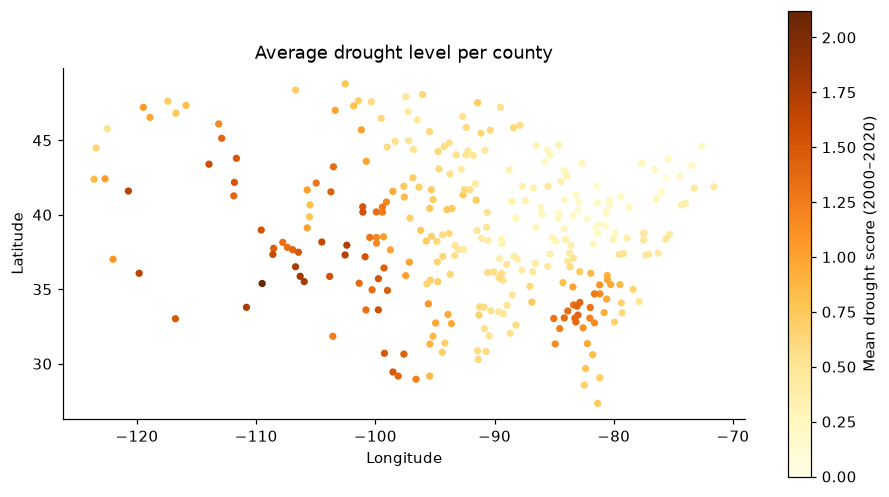

In [21]:
county_mean = weekly.groupby("fips")["score"].mean().rename("mean_score").reset_index()
county_mean = county_mean.merge(soil[["fips", "lat", "lon"]], on="fips")

fig, ax = plt.subplots(figsize=(10, 5.5))
sc = ax.scatter(county_mean["lon"], county_mean["lat"], c=county_mean["mean_score"],
                cmap="YlOrBr", s=14, vmin=0, vmax=county_mean["mean_score"].max())
fig.colorbar(sc, ax=ax, label="Mean drought score (2000–2020)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Average drought level per county")
ax.set_aspect(1.25)
save(fig, "drought_map")
plt.show()

## 6. How persistent is drought?

Transition matrix: for each drought class this week, the share of next week's classes. Rows sum to 100 %.

Saved reports\figures\eda_transition_matrix.png


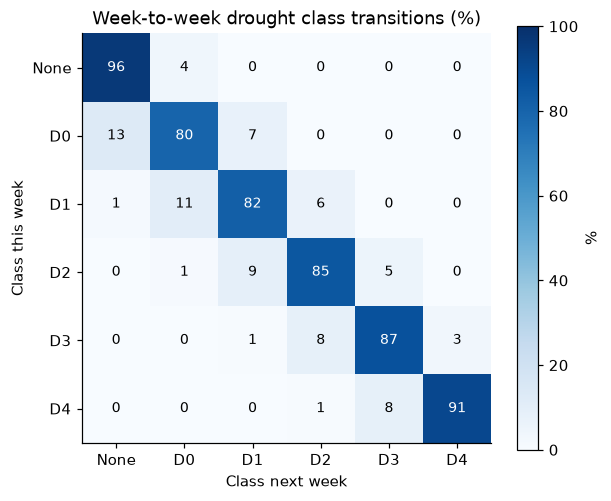

Class unchanged from one week to the next: 90.8 % of county-weeks


In [22]:
w = weekly.sort_values(["fips", "date"])
w["next_class"] = w.groupby(["fips", "split"])["drought_class"].shift(-1)
pairs = w.dropna(subset=["next_class"])
transition = pd.crosstab(pairs["drought_class"], pairs["next_class"].astype(int),
                         normalize="index") * 100
transition = transition.reindex(index=range(6), columns=range(6), fill_value=0)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(transition.values, cmap="Blues", vmin=0, vmax=100)
for i in range(6):
    for j in range(6):
        val = transition.values[i, j]
        ax.text(j, i, f"{val:.0f}", ha="center", va="center",
                color="white" if val > 60 else "black", fontsize=9)
ax.set_xticks(range(6), CLASS_NAMES)
ax.set_yticks(range(6), CLASS_NAMES)
ax.set_xlabel("Class next week")
ax.set_ylabel("Class this week")
ax.set_title("Week-to-week drought class transitions (%)")
fig.colorbar(im, ax=ax, label="%")
save(fig, "transition_matrix")
plt.show()

unchanged = (pairs["drought_class"] == pairs["next_class"]).mean() * 100
print(f"Class unchanged from one week to the next: {unchanged:.1f} % of county-weeks")

**What to look for:** a strong diagonal means drought changes slowly. A model that simply repeats this week's class (the *persistence baseline*) will therefore be very hard to beat one week ahead. The interesting cases are the off-diagonal ones: drought onset (None/D0 → D1) and recovery.

## 7. Seasonality

Saved reports\figures\eda_seasonality.png


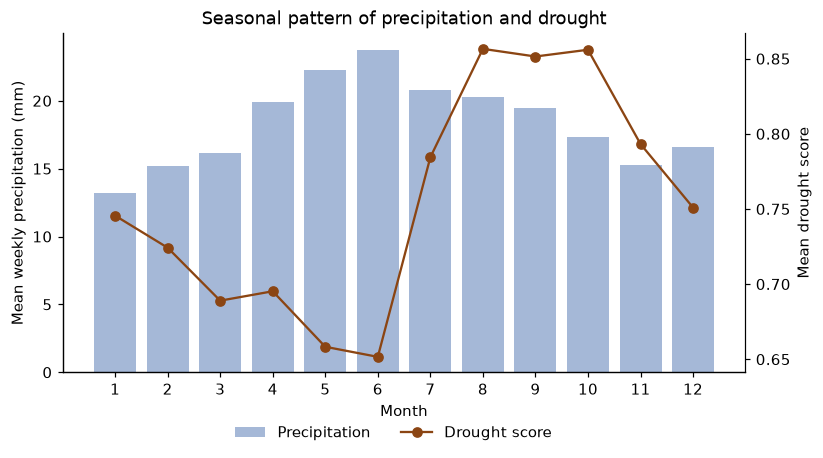

In [23]:
by_month = weekly.assign(month=weekly["date"].dt.month).groupby("month").agg(
    mean_score=("score", "mean"), precip_mm_per_week=("PRECTOT", "mean"), temp_c=("T2M", "mean"))

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.bar(by_month.index, by_month["precip_mm_per_week"], color="#4C72B0", alpha=0.5, label="Precipitation")
ax1.set_ylabel("Mean weekly precipitation (mm)")
ax1.set_xlabel("Month")
ax1.set_xticks(range(1, 13))
ax2 = ax1.twinx()
ax2.plot(by_month.index, by_month["mean_score"], color="#8B4513", marker="o", label="Drought score")
ax2.set_ylabel("Mean drought score")
ax2.spines["right"].set_visible(True)
ax1.set_title("Seasonal pattern of precipitation and drought")
fig.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=2)
save(fig, "seasonality")
plt.show()

## 8. Weather and drought

Drought builds up over weeks, so single-week weather says little. Here we use the feature table from `src/features.py`, which adds rolling sums and means over 4–26 weeks, and correlate the features with the drought score **one week ahead** (the forecasting target).

Saved reports\figures\eda_weather_correlations.png


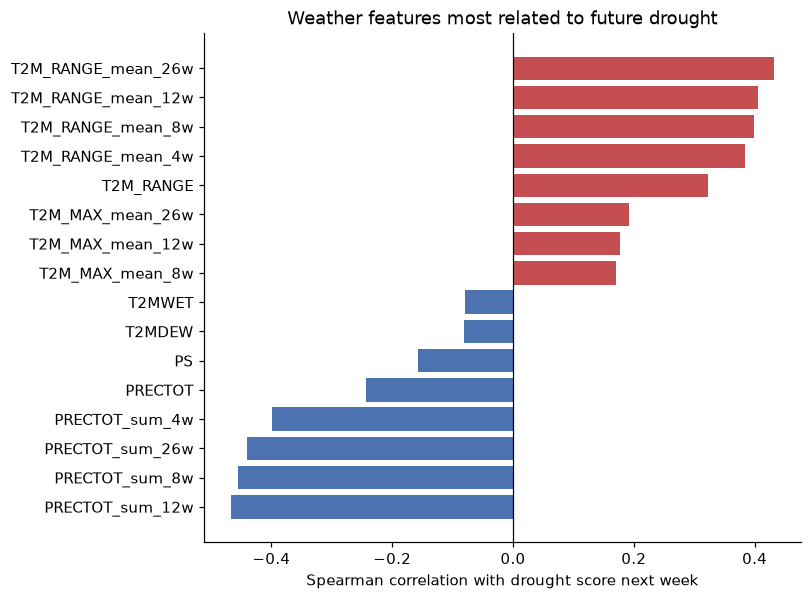

Correlation of the current drought score with next week's score: 0.944


In [24]:
features = add_features(weekly.drop(columns="drought_class"), soil=None, horizon=1)
weather_feats = [c for c in features.columns
                 if any(c.startswith(v) for v in WEATHER_COLS) and c not in {"split"}]
corr = (features[weather_feats + ["target_score"]]
        .corr(method="spearman")["target_score"]
        .drop("target_score")
        .sort_values())
top = pd.concat([corr.head(8), corr.tail(8)])

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index, top.values, color=np.where(top.values < 0, "#4C72B0", "#C44E52"))
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Spearman correlation with drought score next week")
ax.set_title("Weather features most related to future drought")
save(fig, "weather_correlations")
plt.show()

print("Correlation of the current drought score with next week's score:",
      round(features[["score", "target_score"]].corr(method="spearman").iloc[0, 1], 3))

Saved reports\figures\eda_precip_by_class.png


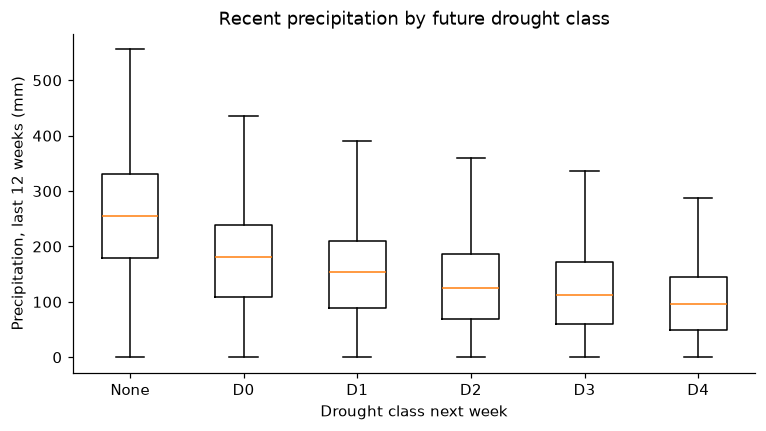

In [25]:
fig, ax = plt.subplots(figsize=(8, 4))
data = [features.loc[features["y"] == k, "PRECTOT_sum_12w"] for k in range(6)]
ax.boxplot(data, showfliers=False)
ax.set_xticks(range(1, 7), CLASS_NAMES)
ax.set_xlabel("Drought class next week")
ax.set_ylabel("Precipitation, last 12 weeks (mm)")
ax.set_title("Recent precipitation by future drought class")
save(fig, "precip_by_class")
plt.show()

## 9. Soil and land characteristics

The soil data are static per county. Their correlation with each county's average drought level shows whether they add information beyond the weather.

Saved reports\figures\eda_soil_correlations.png


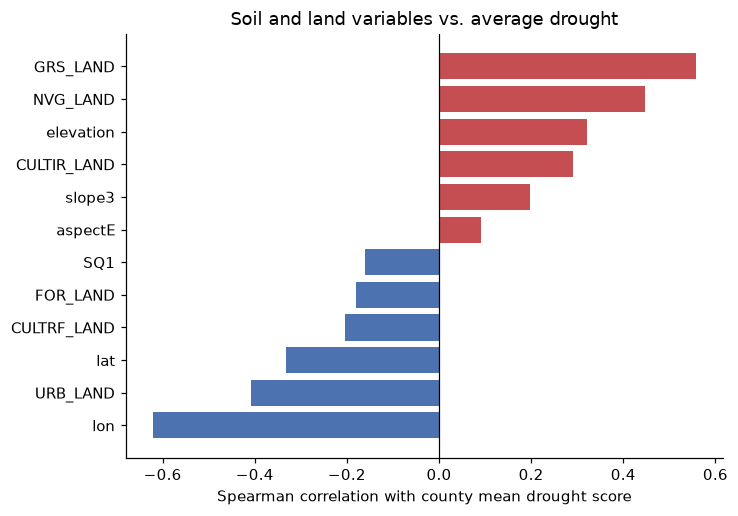

In [26]:
soil_corr = (soil.merge(county_mean[["fips", "mean_score"]], on="fips")
             .drop(columns=["fips"])
             .corr(method="spearman")["mean_score"]
             .drop(["mean_score"])
             .dropna()
             .sort_values())
top_soil = pd.concat([soil_corr.head(6), soil_corr.tail(6)])

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top_soil.index, top_soil.values, color=np.where(top_soil.values < 0, "#4C72B0", "#C44E52"))
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Spearman correlation with county mean drought score")
ax.set_title("Soil and land variables vs. average drought")
save(fig, "soil_correlations")
plt.show()

## 10. Summary of findings

Fill in with the numbers printed above after running on the full selection of counties:

- **Class imbalance:** about __ % of county-weeks have no drought; D3–D4 make up only __ %. → use macro F1 and class weights.
- **Persistence:** the class is unchanged from one week to the next in __ % of cases. → the persistence baseline is the benchmark to beat; onset and recovery are the hard cases.
- **Time:** the worst drought years were __ ; the class mix differs between train, validation and test.
- **Space and season:** drought is more common in __ ; drought scores peak in __ .
- **Weather:** long-window precipitation (8–26 weeks) and temperature are the weather features most related to future drought. → rolling-window features.
- **Soil:** __ .